In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

'2.14.0+cu130'

## Data Preparing and Loading

In [3]:
# Create known parameters
weights = 0.7
bias = 0.3

# create
start = 0
end = 1 
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weights * X + bias

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [4]:
len(X), len(y)

(50, 50)

In [5]:
# Create train test split 
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(X_test), len(y_train)

(40, 10, 40)

In [6]:
X_train, y_train

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800],
         [0.2000],
         [0.2200],
         [0.2400],
         [0.2600],
         [0.2800],
         [0.3000],
         [0.3200],
         [0.3400],
         [0.3600],
         [0.3800],
         [0.4000],
         [0.4200],
         [0.4400],
         [0.4600],
         [0.4800],
         [0.5000],
         [0.5200],
         [0.5400],
         [0.5600],
         [0.5800],
         [0.6000],
         [0.6200],
         [0.6400],
         [0.6600],
         [0.6800],
         [0.7000],
         [0.7200],
         [0.7400],
         [0.7600],
         [0.7800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260],
         [0.4400],
         [0.4540],
         [

In [7]:
def plot_predictions(train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None):
    plt.figure(figsize=(10,7))
    plt.scatter(train_data, train_labels, c="b", s=4, label="Training Data")

    plt.scatter(test_data, test_labels, c="g", s=4, label="Test Data")

    if predictions is not None:
        plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

    plt.legend(prop={'size': 14});

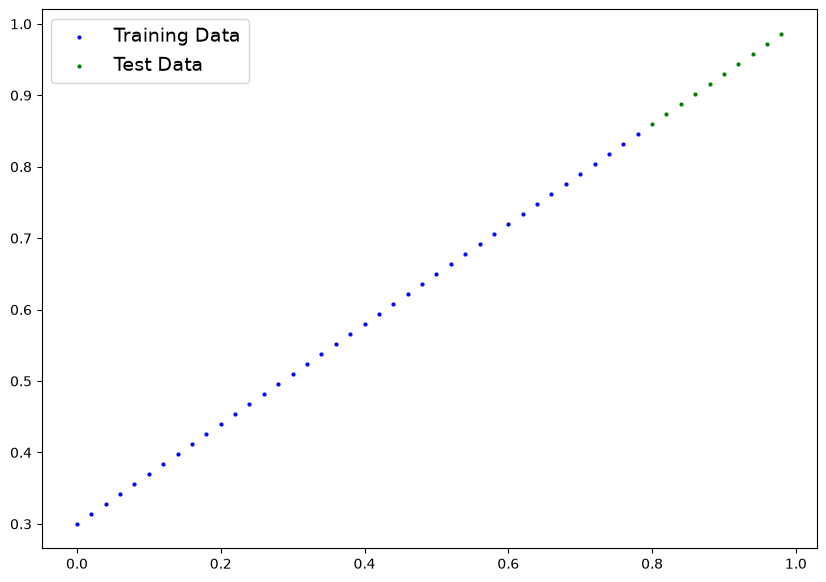

In [8]:
plot_predictions()

# Build first PyTorch model

In [9]:
# Create linear regression model class
class LinearRegressionModel(nn.Module):   # almost everything in PyTorch inherits from nn.Module
    def __init__(self):     # child initialisation = linear Regression 
        super().__init__()   # parent initialisation = nn.Module 
        self.weights = nn.Parameter(torch.randn(1,
                                               requires_grad=True,  # keeps tracks of the gradients 
                                               dtype=torch.float32))
        self.bias = nn.Parameter(torch.randn(1,
                                              requires_grad=True,
                                              dtype=torch.float))

        # Forward method
    def forward(self, x: torch.Tensor):
        return self.weights * x + self.bias  # linear regression formula 

## PyTorch model building essentials 

#### **torch.nn** - contains all of the building for computational graphs a neural netwrork can be considered a computational graph 
#### **torch.nn.Parameter** - what parameters should our model try and learn often a PyTorch layer from torchh.nn will set these for us 
#### **torch.nn.Module** - the base class for all neural networks modules if you subclass it you should overwrite forward()
#### **torch.optim** - this is where the optimizers in PyTorch live they will help with gradient descent
#### def forward() - ALL nn.Module subclasses require you to overwrite forward() this method defines what happens in the forward pass 

### Checking the contents of our PyTorch model and we can check that using .parameters() to see what is inside our model


In [28]:
torch.manual_seed(42)

# create an instance of the model this is a subclass of nn.Module
model_0 = LinearRegressionModel()
model_0

LinearRegressionModel()

In [29]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [30]:
# List named parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [31]:
# Making predictions using torch.inference_mode() let's see how well it predicts y_test based on X_test
with torch.inference_mode():
    y_preds = model_0(X_test)

y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [32]:
y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

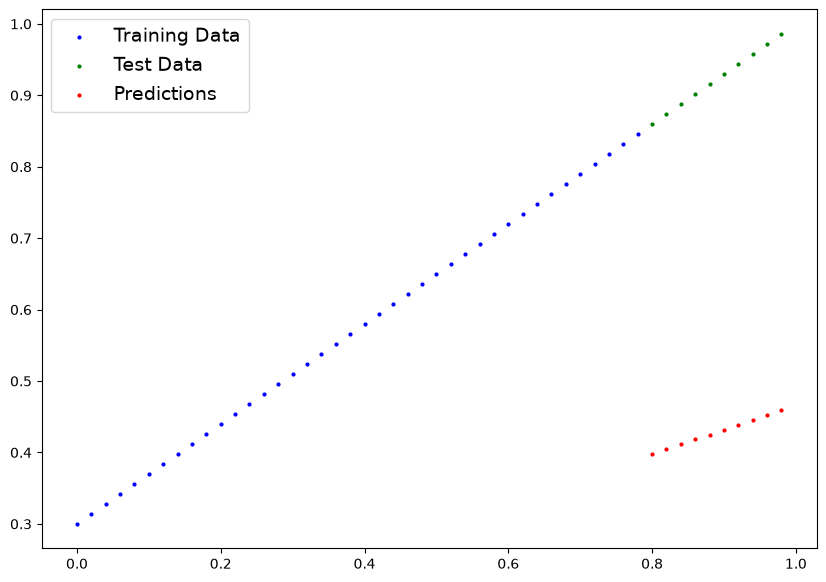

In [33]:
plot_predictions(predictions=y_preds)

# Train the model 

#### Loss Function : A function to measure how wrong your model predictions are to the ideal output 
#### Optimizer : Take into account the loss of a model and adjusts the models parameters eg weights and bias to improve the loss functions

#### And specifically for Pytorch we need:
**A Training Loop**

**A Testing Loop**

In [34]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [35]:
# Setup a loss function 
loss_fn = nn.L1Loss()

# Setup optimizer 
optimizer = torch.optim.SGD(params=model_0.parameters(),
                           lr=0.01)

## Build a Training and Testing Loop in PyTorch

#### A couple of things we need in training loop:
##### 0. Loop through the data
##### 1. Forward pass  (this involves data moving through our model), forward() functions
##### 2. Calculate the loss compare forward pass predicitons to ground truth labels 
##### 3. Optimizer zero grad
##### 4. Loss backward (backprop) moves backwards through the network to calculate the gradients with respect to loss to upate the weights and biases
##### 5. Optimizer step - use the optimizer to adjust our model parameters to try and improve the loss

In [36]:
# An epoch is one loop through the data 
epochs = 165  # 1 indiactes 1 forward pass thorugh the data 

#Track different values 
epoch_count = []
loss_values = []
test_loss_values = []

### Training
# 0. loop through the data 
for epoch in range(epochs):
    # set the model to training mode 
    model_0.train()  # train mode in Pytorch sets all the parameters requires gradient

    # 1. Forward pass 
    y_pred = model_0(X_train)

    #2. Calcualte loss
    loss = loss_fn(y_pred, y_train)
    print(f'Loss : {loss}')

    #3. Optimizer zero grad
    optimizer.zero_grad()

    #4. Backprop
    loss.backward()

    #5. Step the optimizer 
    optimizer.step()

    ### Testing 
    model_0.eval() # turns off different settings in the model not needed for evaluation (dropout, BatchNorm layers)
    with torch.inference_mode():   # turns of gradient tracking 
        # 1. Do the forward pass 
        test_pred = model_0(X_test)

        # 2. Calculate the loss
        test_loss = loss_fn(test_pred, y_test)

    if epoch % 10 == 0:
        epoch_count.append(epoch)
        loss_values.append(loss)
        test_loss_values.append(test_loss)
    print(f"Epoch: {epoch} | Test : {loss} | Test Loss: {test_loss}")
    #print out model state_dict()
    print(model_0.state_dict())
    


Loss : 0.31288138031959534
Epoch: 0 | Test : 0.31288138031959534 | Test Loss: 0.48106518387794495
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388])})
Loss : 0.3013603389263153
Epoch: 1 | Test : 0.3013603389263153 | Test Loss: 0.4675942063331604
OrderedDict({'weights': tensor([0.3445]), 'bias': tensor([0.1488])})
Loss : 0.28983935713768005
Epoch: 2 | Test : 0.28983935713768005 | Test Loss: 0.4541231691837311
OrderedDict({'weights': tensor([0.3484]), 'bias': tensor([0.1588])})
Loss : 0.2783183455467224
Epoch: 3 | Test : 0.2783183455467224 | Test Loss: 0.44065219163894653
OrderedDict({'weights': tensor([0.3523]), 'bias': tensor([0.1688])})
Loss : 0.26679736375808716
Epoch: 4 | Test : 0.26679736375808716 | Test Loss: 0.4271811842918396
OrderedDict({'weights': tensor([0.3562]), 'bias': tensor([0.1788])})
Loss : 0.2552763521671295
Epoch: 5 | Test : 0.2552763521671295 | Test Loss: 0.41371020674705505
OrderedDict({'weights': tensor([0.3601]), 'bias': tensor([0.1888])})
Loss : 

In [37]:
weights, bias

(0.7, 0.3)

In [38]:
with torch.inference_mode():
    y_preds_new = model_0(X_test)

In [39]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.6894])), ('bias', tensor([0.3043]))])

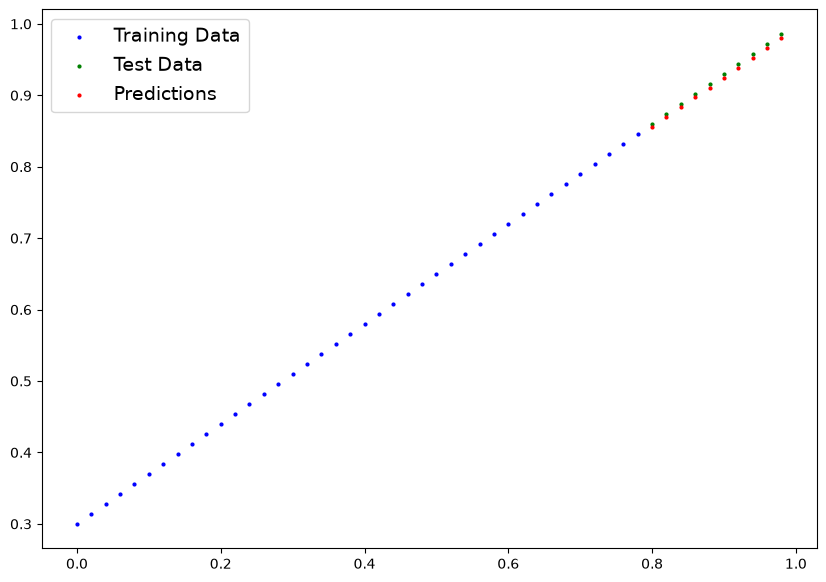

In [40]:
plot_predictions(predictions=y_preds_new)

In [45]:
epoch_count, loss_values, test_loss_values

([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160],
 [tensor(0.3129, grad_fn=<MeanBackward0>),
  tensor(0.1977, grad_fn=<MeanBackward0>),
  tensor(0.0891, grad_fn=<MeanBackward0>),
  tensor(0.0531, grad_fn=<MeanBackward0>),
  tensor(0.0454, grad_fn=<MeanBackward0>),
  tensor(0.0417, grad_fn=<MeanBackward0>),
  tensor(0.0382, grad_fn=<MeanBackward0>),
  tensor(0.0348, grad_fn=<MeanBackward0>),
  tensor(0.0313, grad_fn=<MeanBackward0>),
  tensor(0.0279, grad_fn=<MeanBackward0>),
  tensor(0.0245, grad_fn=<MeanBackward0>),
  tensor(0.0210, grad_fn=<MeanBackward0>),
  tensor(0.0176, grad_fn=<MeanBackward0>),
  tensor(0.0142, grad_fn=<MeanBackward0>),
  tensor(0.0107, grad_fn=<MeanBackward0>),
  tensor(0.0073, grad_fn=<MeanBackward0>),
  tensor(0.0039, grad_fn=<MeanBackward0>)],
 [tensor(0.4811),
  tensor(0.3464),
  tensor(0.2173),
  tensor(0.1446),
  tensor(0.1136),
  tensor(0.0992),
  tensor(0.0889),
  tensor(0.0806),
  tensor(0.0723),
  tensor(0.0647),
  tensor(0.

# Saving a Model in PyTorch

#### Three main methods:
##### 1. `torch.save()` - allows you save a PyTorch object in Python pickle format
##### 2. `torch.load()` - allows you to load a saved Pytorch object 
##### 3. `torch.nn.Module.load_state_dict` - this allows to load a model's saved parameters or state dictionary(parameters) state_dict()

In [48]:
# Saving our models
from pathlib import Path

#1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

#2. Creaet model save path 
MODEL_NAME = "01_Pytorch_Workflow_model__0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

#3. Save the model
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(),
          f=MODEL_SAVE_PATH)



Saving model to: models\01_Pytorch_Workflow_model__0.pth


In [49]:
model_0

LinearRegressionModel()

# Loading a Model

#### Since we saved our model state_dict() - (parameters) rather than the entire model we will create a new instance of our model class and load the saved state_dict() inot that.

In [53]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.6894])), ('bias', tensor([0.3043]))])

In [54]:
#To load in a save state dict we have to instantiate a new instance of our model class
loaded_model_0 = LinearRegressionModel()

#load the save state_dict() of model_0
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [56]:
loaded_model_0.state_dict()

OrderedDict([('weights', tensor([0.6894])), ('bias', tensor([0.3043]))])